In [1]:
import pandas as pd


In [3]:
df=pd.read_csv(r"C:\Users\MOUNIKA\Downloads\archive (15)\all_tickets_processed_improved_v3.csv")
print(df)

                                                Document    Topic_group
0      connection with icon icon dear please setup ic...       Hardware
1      work experience user work experience user hi w...         Access
2      requesting for meeting requesting meeting hi p...       Hardware
3      reset passwords for external accounts re expir...         Access
4      mail verification warning hi has got attached ...  Miscellaneous
...                                                  ...            ...
47832  git space for a project issues with adding use...         Access
47833  error sent july error hi guys can you help out...  Miscellaneous
47834  connection issues sent tuesday july connection...       Hardware
47835  error cube reports sent tuesday july error hel...     HR Support
47836  running out on extensions hello please be advi...       Hardware

[47837 rows x 2 columns]


In [4]:
print(df.shape)
print(df.columns)
print(df.head())

(47837, 2)
Index(['Document', 'Topic_group'], dtype='object')
                                            Document    Topic_group
0  connection with icon icon dear please setup ic...       Hardware
1  work experience user work experience user hi w...         Access
2  requesting for meeting requesting meeting hi p...       Hardware
3  reset passwords for external accounts re expir...         Access
4  mail verification warning hi has got attached ...  Miscellaneous


In [5]:
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Document     47837 non-null  object
 1   Topic_group  47837 non-null  object
dtypes: object(2)
memory usage: 747.6+ KB
None

Missing values:
 Document       0
Topic_group    0
dtype: int64

Duplicate rows: 0


In [6]:
print(df['Topic_group'].value_counts())
print()
print(df['Topic_group'].value_counts(normalize=True).round(3) * 100)

Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64

Topic_group
Hardware                 28.5
HR Support               22.8
Access                   14.9
Miscellaneous            14.8
Storage                   5.8
Purchase                  5.2
Internal Project          4.4
Administrative rights     3.7
Name: proportion, dtype: float64


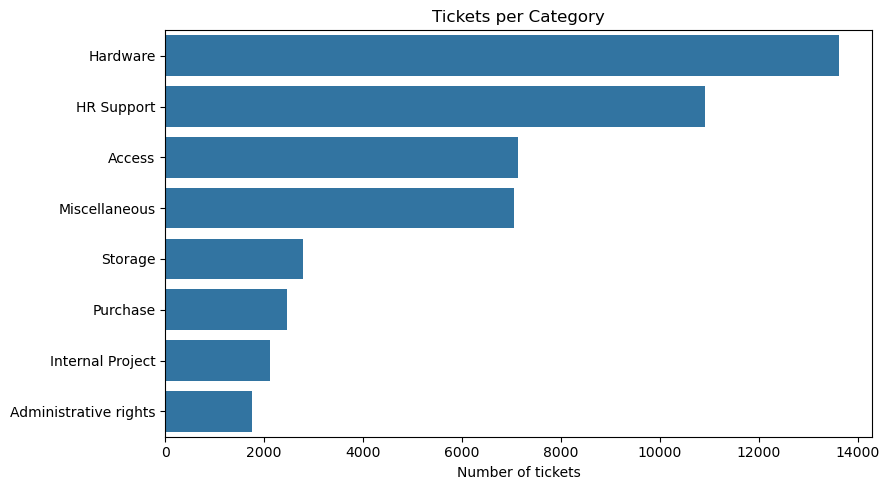

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9,5))
sns.countplot(data=df, y='Topic_group', order=df['Topic_group'].value_counts().index)
plt.title("Tickets per Category")
plt.xlabel("Number of tickets")
plt.ylabel("")
plt.tight_layout()
plt.savefig("category_distribution.png", dpi=150)   # keep this for your GitHub images/ folder
plt.show()

count    47837.000000
mean        43.597341
std         56.736800
min          2.000000
25%         17.000000
50%         26.000000
75%         46.000000
max        981.000000
Name: word_count, dtype: float64


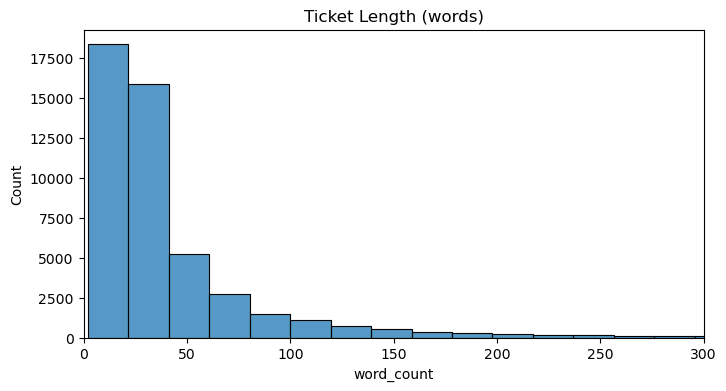

In [8]:
df['word_count'] = df['Document'].astype(str).str.split().str.len()
print(df['word_count'].describe())

plt.figure(figsize=(8,4))
sns.histplot(df['word_count'], bins=50)
plt.title("Ticket Length (words)")
plt.xlim(0, 300)
plt.show()

In [9]:
for cat in df['Topic_group'].unique():
    print(f"\n=== {cat} ===")
    print(df[df['Topic_group'] == cat]['Document'].iloc[0][:300])


=== Hardware ===
connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead

=== Access ===
work experience user work experience user hi work experience student coming next his name much appreciate him duration thank

=== Miscellaneous ===
mail verification warning hi has got attached please addresses best regards monitoring analyst verification warning

=== HR Support ===
access request dear modules report report cost thank much regards

=== Purchase ===
system hello movement has left available device please kind device denmark copenhagen denmark please source quotation shipping by lead

=== Administrative rights ===
notification wireless devices upgrade cr medium wireless devices upgrade cr medium hi please announce users about window wireless best regards senior engineer cr medium has by hello summary software upgrade release has approved by please wait until completed starting kind regards ref msg

=== Storage ===
mailbox almost

In [10]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\MOUNIKA\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\MOUNIKA\AppData\Roaming\nltk_data...


True

In [12]:
stop_words = set(stopwords.words('english'))

# greetings / sign-offs that carry no category meaning
extra_stop = {'hi','hello','dear','please','thanks','thank','regards','best','kind',
              'much','appreciate','would','could','also','get','let','know','need',
              'hey','team','good','morning','afternoon','sent','msg','ref'}
stop_words |= extra_stop

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)          # keep letters only
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words
             if w not in stop_words and len(w) > 2]
    return ' '.join(words)

In [13]:
df['clean_text'] = df['Document'].apply(clean_text)

In [14]:
for i in range(3):
    print("BEFORE:", df['Document'].iloc[i][:200])
    print("AFTER :", df['clean_text'].iloc[i][:200])
    print()

print("Empty after cleaning:", (df['clean_text'].str.strip() == '').sum())

BEFORE: connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead
AFTER : connection icon icon setup icon per icon engineer detail needed lead

BEFORE: work experience user work experience user hi work experience student coming next his name much appreciate him duration thank
AFTER : work experience user work experience user work experience student coming next name duration

BEFORE: requesting for meeting requesting meeting hi please help follow equipments cable pc cord plug
AFTER : requesting meeting requesting meeting help follow equipment cable cord plug

Empty after cleaning: 3


In [15]:
df = df[df['clean_text'].str.strip() != ''].reset_index(drop=True)
print(df.shape)
df.to_csv("cleaned_tickets.csv", index=False)

(47834, 4)


In [16]:
from sklearn.model_selection import train_test_split

X = df['clean_text']
y = df['Topic_group']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape[0], " Test:", X_test.shape[0])

Train: 38267  Test: 9567


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Linear SVM": LinearSVC(class_weight='balanced'),
}

results = []
trained = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=30000, min_df=2)),
        ("clf", clf)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    trained[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average='macro', zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average='macro', zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average='macro'),
    })
    print(f"{name} done")

results_df = pd.DataFrame(results).round(4).sort_values("F1 (macro)", ascending=False)
results_df

Naive Bayes done
Logistic Regression done
Linear SVM done


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
2,Linear SVM,0.8525,0.8500,0.8576,0.8534
1,Logistic Regression,0.8504,0.8328,0.8734,0.8505
0,Naive Bayes,0.7662,0.8845,0.6625,0.7217


In [18]:
from sklearn.metrics import classification_report

best_name = results_df.iloc[0]["Model"]
print("Best model:", best_name)
best_model = trained[best_name]
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))

Best model: Linear SVM
                       precision    recall  f1-score   support

               Access       0.90      0.91      0.90      1425
Administrative rights       0.79      0.76      0.77       352
           HR Support       0.86      0.85      0.85      2183
             Hardware       0.84      0.82      0.83      2723
     Internal Project       0.81      0.88      0.85       424
        Miscellaneous       0.82      0.84      0.83      1412
             Purchase       0.92      0.90      0.91       493
              Storage       0.86      0.90      0.88       555

             accuracy                           0.85      9567
            macro avg       0.85      0.86      0.85      9567
         weighted avg       0.85      0.85      0.85      9567



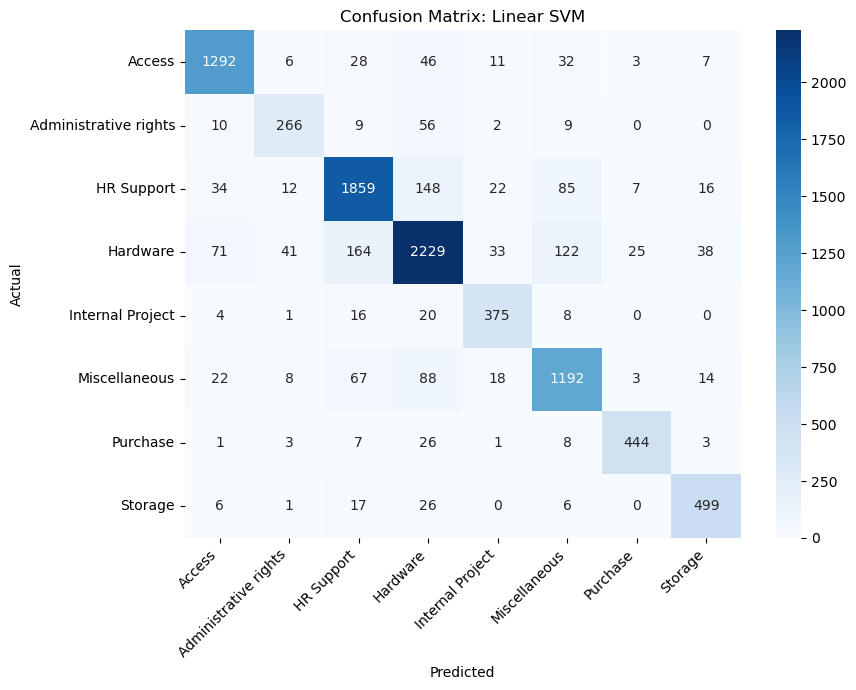

In [19]:
from sklearn.metrics import confusion_matrix

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion Matrix: {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [20]:
HIGH_WORDS = ['urgent', 'urgently', 'asap', 'immediately', 'critical', 'emergency',
              'outage', 'down', 'crash', 'crashed', 'not working', 'cannot access',
              'cant access', 'unable to', 'locked out', 'blocked', 'breach',
              'hacked', 'virus', 'security', 'data loss', 'failed', 'failure']

MEDIUM_WORDS = ['error', 'issue', 'problem', 'slow', 'bug', 'fault', 'delay',
                'expired', 'expire', 'warning', 'full', 'almost full', 'reset',
                'missing', 'broken']

MEDIUM_CATEGORIES = ['Access', 'Administrative rights', 'Storage']

def assign_priority(text, category):
    t = ' ' + str(text).lower() + ' '
    if any(f' {w} ' in t for w in HIGH_WORDS):
        return 'High'
    if any(f' {w} ' in t for w in MEDIUM_WORDS) or category in MEDIUM_CATEGORIES:
        return 'Medium'
    return 'Low'

df['priority'] = df.apply(lambda r: assign_priority(r['Document'], r['Topic_group']), axis=1)

In [21]:
print(df['priority'].value_counts())
print()
print(df['priority'].value_counts(normalize=True).round(3) * 100)
print()
print(pd.crosstab(df['Topic_group'], df['priority']))

priority
Low       24465
Medium    17224
High       6145
Name: count, dtype: int64

priority
Low       51.1
Medium    36.0
High      12.8
Name: proportion, dtype: float64

priority               High   Low  Medium
Topic_group                              
Access                  880     0    6244
Administrative rights   386     0    1373
HR Support              724  7440    2751
Hardware               2926  7627    3063
Internal Project        224  1721     174
Miscellaneous           715  5312    1033
Purchase                 49  2365      50
Storage                 241     0    2536


In [22]:
for p in ['High', 'Medium', 'Low']:
    print(f"\n=== {p} ===")
    for t in df[df['priority'] == p]['Document'].sample(3, random_state=1):
        print("-", t[:200])


=== High ===
- issues with accessing hello could we set up call resolve issue kind regards engineer en sent monday december issues with accessing hello could you please look into why cannot access she initially was 
- pas rights rights dear kind give rights modify unknown pipelines possible asap update forecast greetings
- not working can send any since yesterday receiving but can send need help asap thanks

=== Medium ===
- time card error sent friday card error hello have issue when trying log status card error when try delete leave wed able could you please help with issue mentioned thanks senior software tester
- access to confluence needed november confluence hello wanted confluence about information found out somehow please provide membership doing wrong while logging currently logging without part cant erro
- lost access card sent friday december lost access card hello would like inform you lost access card regards design lead en

=== Low ===
- eel access eel hi please help get

In [23]:
Xp = df['Document']
yp = df['priority']

Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    Xp, yp, test_size=0.2, stratify=yp, random_state=42)

print("Train:", Xp_train.shape[0], " Test:", Xp_test.shape[0])

Train: 38267  Test: 9567


In [24]:
prio_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Linear SVM": LinearSVC(class_weight='balanced'),
}

prio_results = []
prio_trained = {}

for name, clf in prio_models.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 3), max_features=50000, min_df=2)),
        ("clf", clf)
    ])
    pipe.fit(Xp_train, yp_train)
    pred = pipe.predict(Xp_test)
    prio_trained[name] = pipe
    prio_results.append({
        "Model": name,
        "Accuracy": accuracy_score(yp_test, pred),
        "Precision (macro)": precision_score(yp_test, pred, average='macro'),
        "Recall (macro)": recall_score(yp_test, pred, average='macro'),
        "F1 (macro)": f1_score(yp_test, pred, average='macro'),
    })
    print(f"{name} done")

prio_df = pd.DataFrame(prio_results).round(4).sort_values("F1 (macro)", ascending=False)
prio_df

Logistic Regression done
Linear SVM done


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
1,Linear SVM,0.9181,0.9279,0.9071,0.9168
0,Logistic Regression,0.9019,0.8952,0.8917,0.8932


In [25]:
best_prio_name = prio_df.iloc[0]["Model"]
best_prio = prio_trained[best_prio_name]
yp_pred = best_prio.predict(Xp_test)

print("Best priority model:", best_prio_name)
print(classification_report(yp_test, yp_pred, digits=3))

Best priority model: Linear SVM
              precision    recall  f1-score   support

        High      0.958     0.892     0.924      1229
         Low      0.912     0.956     0.933      4893
      Medium      0.914     0.873     0.893      3445

    accuracy                          0.918      9567
   macro avg      0.928     0.907     0.917      9567
weighted avg      0.918     0.918     0.918      9567



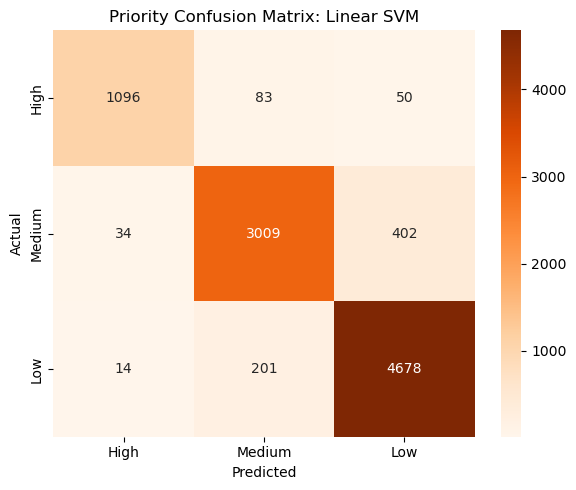

In [26]:
prio_labels = ['High', 'Medium', 'Low']
cm_p = confusion_matrix(yp_test, yp_pred, labels=prio_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_p, annot=True, fmt='d', cmap='Oranges',
            xticklabels=prio_labels, yticklabels=prio_labels)
plt.title(f"Priority Confusion Matrix: {best_prio_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("priority_confusion_matrix.png", dpi=150)
plt.show()

In [27]:
best_cat = trained["Linear SVM"]        # category model (uses clean_text)
best_prio = prio_trained["Linear SVM"]  # priority model (uses original text)

def triage(ticket_text):
    cat = best_cat.predict([clean_text(ticket_text)])[0]
    prio = best_prio.predict([str(ticket_text).lower()])[0]
    return {"category": cat, "priority": prio}

In [28]:
examples = [
    "my laptop screen is not working and i have a client meeting asap",
    "i cannot access my email account, locked out since this morning",
    "please send a quotation for ten new monitors",
    "mailbox almost full, need more storage space",
    "need admin rights to install software on my pc",
    "how do i fill the maternity leave form",
]

for t in examples:
    print(t)
    print("   ->", triage(t))
    print()

my laptop screen is not working and i have a client meeting asap
   -> {'category': 'Hardware', 'priority': 'High'}

i cannot access my email account, locked out since this morning
   -> {'category': 'Access', 'priority': 'High'}

please send a quotation for ten new monitors
   -> {'category': 'Hardware', 'priority': 'Low'}

mailbox almost full, need more storage space
   -> {'category': 'Storage', 'priority': 'Medium'}

need admin rights to install software on my pc
   -> {'category': 'Administrative rights', 'priority': 'Medium'}

how do i fill the maternity leave form
   -> {'category': 'HR Support', 'priority': 'Low'}



In [29]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump(best_cat, "models/category_model.pkl")
joblib.dump(best_prio, "models/priority_model.pkl")
print(os.listdir("models"))

['category_model.pkl', 'priority_model.pkl']


In [30]:
results_df.to_csv("category_model_results.csv", index=False)
prio_df.to_csv("priority_model_results.csv", index=False)

In [31]:
print("Category model  -> Accuracy: %.3f | Macro F1: %.3f" % (results_df.iloc[0]['Accuracy'], results_df.iloc[0]['F1 (macro)']))
print("Priority model  -> Accuracy: %.3f | Macro F1: %.3f" % (prio_df.iloc[0]['Accuracy'], prio_df.iloc[0]['F1 (macro)']))

Category model  -> Accuracy: 0.853 | Macro F1: 0.853
Priority model  -> Accuracy: 0.918 | Macro F1: 0.917


readme = """# FUTURE_ML_02 - Support Ticket Classification & Prioritization

A machine learning system that reads IT support tickets, classifies them into a category, and assigns a priority level (High / Medium / Low) so support teams can respond faster.

## Problem
Support teams receive thousands of tickets. Sorting them by hand is slow, and urgent issues get delayed. This project automates category sorting and priority tagging.

## Dataset
IT Service Ticket Classification Dataset (Kaggle, adisongoh): 47,837 tickets, 8 categories (Hardware, HR Support, Access, Miscellaneous, Storage, Purchase, Internal Project, Administrative rights). The text was already cleaned in the dataset.
Link: https://www.kaggle.com/datasets/adisongoh/it-service-ticket-classification-dataset

## Approach
1. Explore the data: class balance, ticket length.
2. Clean the text: lowercase, keep letters only, remove stopwords and greetings, lemmatize (NLTK).
3. Convert text to numbers with TF-IDF (unigrams and bigrams).
4. Train and compare Naive Bayes, Logistic Regression and Linear SVM (80/20 stratified split).
5. Assign priority with keyword rules, then train models to predict it.
6. Evaluate with accuracy, precision, recall, F1 and confusion matrices.

## How priority is decided
The dataset has no priority column, so priority labels were created with rules:
- High: urgent words such as urgent, asap, critical, outage, locked out, cannot access, failed.
- Medium: problem words such as error, issue, slow, expired, warning, or a category that is usually important (Access, Administrative rights, Storage).
- Low: everything else.

## Results
| Task | Best model | Accuracy | Macro F1 |
|------|-----------|----------|----------|
| Category | Linear SVM | 85.3% | 0.853 |
| Priority | Linear SVM | 91.8% | 0.917 |

- Strongest categories: Purchase and Access. Weakest: Administrative rights.
- Hardware tickets are most often confused with HR Support.
- Charts: category_distribution.png, confusion_matrix.png, priority_confusion_matrix.png

## Limitations
- Priority labels come from keyword rules, so the priority score shows how well the model learned those rules, not real-world urgency. Real labelled priorities would give a more reliable result.
- Some tickets are misclassified, for example a quotation request for monitors was predicted as Hardware instead of Purchase.
- Access, Administrative rights and Storage tickets are never Low priority under the current rules.

## Files
- ticket_classification.ipynb : full code
- category_model_results.csv, priority_model_results.csv : model comparison
- confusion_matrix.png, priority_confusion_matrix.png, category_distribution.png : charts
- requirements.txt : libraries needed

## How to run
1. Download the dataset from the Kaggle link above.
2. pip install -r requirements.txt
3. Open the notebook and change the CSV path in the second cell to your file location.
4. Run all cells.

## Tools
Python, pandas, NLTK, scikit-learn, seaborn, matplotlib, Jupyter Notebook
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

with open("requirements.txt", "w") as f:
    f.write("pandas\nnumpy\nscikit-learn\nnltk\nmatplotlib\nseaborn\njoblib\n")

print("README.md and requirements.txt created")